# Before the Breach: findings, evidence and model

**IBM track, Sheridan Datathon 2026.** This notebook is the demo version of our work: every claim we present, the evidence behind it, and how the model was built and validated. Each number is computed in this notebook, so every claim sits next to its proof.

**The problem.** 72,670 vulnerabilities (CVEs) were published January-September 2026 without being on CISA's Known Exploited Vulnerabilities list (KEV). Rank them so the top 500 holds as many as possible that CISA adds by November 4, using only what was known at each CVE's snapshot month. Standard rankings find 6-8.

**The workflow, in order**
1. **Build a fair practice test (backtest):** replay the benchmark on 2025, where the answers are known.
2. **Audit for leakage:** find columns that reveal the answer, and remove them.
3. **Explore, then confirm:** form ideas on 2024-2025, then test them on 2022-2023 CVEs, which weren't used to form them.
4. **Select the model with repeated cross-validation**, and test the gain over the baseline statistically.
5. **Report what didn't work,** with the evidence.

**Headline results**

| Result | Evidence | Strength |
| --- | --- | --- |
| Our ranking finds about 57% more later-exploited CVEs than the best standard method | ~35 vs. 22 of 85 in the top 0.69%; +13, 90% range +6 to +21, p = 0.001 | Cross-validated, paired bootstrap |
| Who reports the bug predicts exploitation | Odds × 2.6 per standard deviation of the assigner's past KEV rate | Confirmed on holdout |
| CVEs released alone or in small batches are riskier | 2.6x vs. batches of 51+; holds within assigners | Confirmed on holdout |
| Network + no login + no click is riskier | 2.8x; holds within assigners | Confirmed on holdout |
| XSS and WordPress CVEs essentially never reach KEV | 0 of 8,573 and 0 of 3,804 | Confirmed on holdout |
| CVSS separates risk less among high scores | AUC 0.71 overall vs. 0.60 among CVSS 9+ (difference 0.11, CI 0.03-0.18) | Confirmed on holdout |
| NIST's review status leaks the answer | 0 positives among 16,722 unreviewed CVEs; a single "reviewed" flag inflates the score | Exploratory (same years) |

Requirements: `features.py` and `features_extra.py` next to this notebook; the data in `../data/`; optionally the Granite text-model scores in `../data/track_b/`. `pip install duckdb pandas numpy scikit-learn lightgbm statsmodels scipy matplotlib`. Run time about 6 minutes.

## 1. Setup

In [1]:
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import duckdb, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from sklearn.metrics import roc_auc_score

DATA = next(p for p in [Path("../data"), Path("data")] if p.exists()).resolve()
FEAT = DATA / "features"
con = duckdb.connect()
TEXT_COLS = "types={'version':'VARCHAR','update':'VARCHAR','version_start_including':'VARCHAR','version_start_excluding':'VARCHAR','version_end_including':'VARCHAR','version_end_excluding':'VARCHAR'}, "
for t in ["vulnerabilities", "affected_products", "references", "known_exploited", "exploit_signals_2024",
          "exploit_signals_2025", "weakness_types", "scoreboard_2026"]:
    extra = TEXT_COLS if t == "affected_products" else ""
    con.sql(f"""CREATE VIEW "{t}" AS SELECT * FROM read_csv('{DATA}/{t}.csv', quote='"', escape='"', {extra}sample_size=-1)""")
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)

BLUE, ORANGE, AQUA, GRAY, INK, INK2 = "#2a78d6", "#eb6834", "#1baf7a", "#b9b8b2", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 12.5, "axes.titleweight": "bold",
    "axes.titlecolor": INK, "axes.titlelocation": "left", "font.size": 10.5, "axes.grid": True,
    "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True, "figure.dpi": 110, "legend.frameon": False})

def per_1000(d, mask):
    """Rows, positives and exploited-per-1,000 for a subset of a labelled set."""
    s = d[mask]
    return {"rows": len(s), "positives": int(s.y.sum()), "per 1,000": round(s.y.mean() * 1000, 2) if len(s) else np.nan}

import features as F, features_extra as FX
import lightgbm as lgb
from scipy import stats
from scipy.stats import rankdata
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import statsmodels.api as sm
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.multitest import multipletests

def topk(yv, s, frac=0.0069):
    """Positives among the top `frac` of rows, ranked by score s (ties broken by row order)."""
    k = int(round(len(yv) * frac)); return int(np.asarray(yv)[np.argsort(-np.asarray(s, dtype=float), kind="stable")[:k]].sum())
def paired_boot(yv, a, b, frac=0.0069, n=2000, seed=0):
    """Paired bootstrap: hits of A minus hits of B in the top `frac`, its 90% range, and one-sided p (share of resamples where A doesn't win)."""
    yv = np.asarray(yv); k = int(round(len(yv) * frac))
    ra, rb = rankdata(-np.asarray(a, dtype=float), method="ordinal"), rankdata(-np.asarray(b, dtype=float), method="ordinal")
    rng = np.random.default_rng(seed); d = np.empty(n)
    for i in range(n):
        idx = rng.integers(0, len(yv), len(yv))
        d[i] = yv[idx][np.argpartition(ra[idx], k)[:k]].sum() - yv[idx][np.argpartition(rb[idx], k)[:k]].sum()
    return topk(yv, a, frac) - topk(yv, b, frac), (int(np.quantile(d, .05)), int(np.quantile(d, .95))), round(float((d <= 0).mean()), 4)
def rate_ratio(y1, n1, y0, n0):
    """Rate ratio with a 95% CI (log method), or an exact one-sided upper bound when the first group has 0 positives."""
    r0 = y0 / n0
    if y1 == 0:
        return 0.0, (0.0, stats.beta.ppf(0.95, 1, n1) / r0)
    rr = (y1 / n1) / r0; se = np.sqrt(1 / y1 - 1 / n1 + 1 / y0 - 1 / n0)
    return rr, (rr * np.exp(-1.96 * se), rr * np.exp(1.96 * se))
def cp_ci(x, n):
    """Clopper-Pearson exact 95% CI for a rate."""
    return (stats.beta.ppf(0.025, x, n - x + 1) if x > 0 else 0.0, stats.beta.ppf(0.975, x + 1, n - x))

## 2. The practice test (backtest)

The 2026 answers are hidden, so the benchmark is rebuilt on past years with the same rules:

- **Rows:** CVEs published January-September that were *not* on KEV by the end of their publish month.
- **Label:** 1 if CISA added the CVE to KEV after the publish month and by December 31.
- **Signals:** EPSS (a 0-1 estimate of attack in the next 30 days) and public exploit-code flags *from the publish month*, which is what was known then.
- **Metric:** positives in the top 0.69% of the ranking: the same share as the judges' 500 of 72,670.

| Set | Published | Role |
| --- | --- | --- |
| 2024 | Jan-Sep 2024 | Training |
| 2025 | Jan-Sep 2025 | Validation (the stand-in for 2026) |
| 2022-2023 | All of 2022-2023 | **Holdout** for confirming findings, never used to form them |

In [2]:
FLAGS = ["exploitdb", "metasploit", "nuclei", "poc_github"]
def eval_set(start, end, deadline, signals):
    flags = ", ".join(f"COALESCE(CAST(s.{f} AS INT), 0) AS {f}" for f in FLAGS)
    return con.sql(f"""
        WITH v AS (SELECT *, CAST(published AS DATE) AS pub FROM vulnerabilities),
             k AS (SELECT cve_id, MIN(CAST(date_added AS DATE)) AS date_added FROM known_exploited GROUP BY cve_id)
        SELECT v.cve_id, v.pub AS published, strftime(v.pub, '%Y-%m') AS snap, v.assigner, v.description, v.nvd_status,
               CAST(v.cvss3_score AS DOUBLE) AS cvss3_score, v.attack_vector, v.attack_complexity, v.privileges_required,
               v.user_interaction, v.scope, v.cwe_ids, CAST(s.epss AS DOUBLE) AS epss, {flags},
               CAST(k.date_added IS NOT NULL AND k.date_added <= DATE '{deadline}' AS INT) AS y
        FROM v LEFT JOIN k USING (cve_id)
        LEFT JOIN {signals} s ON s.cve_id = v.cve_id AND s.month = strftime(v.pub, '%Y-%m')
        WHERE v.pub BETWEEN DATE '{start}' AND DATE '{end}' AND (k.date_added IS NULL OR k.date_added > last_day(v.pub))
        ORDER BY v.cve_id""").df()
train = eval_set("2024-01-01", "2024-09-30", "2024-12-31", "exploit_signals_2024")
val = eval_set("2025-01-01", "2025-09-30", "2025-12-31", "exploit_signals_2025")
hist, hx = F.History(con), FX.ExtraHistory(con)
build = lambda d: FX.add_engineered_features(F.build_features(d, hist), hx)
tr, va = build(train), build(val)
sb = build(F.scoreboard_frame(con).sort_values("cve_id").reset_index(drop=True))
print(f"2024: {len(tr):,} rows, {tr.y.sum()} positives ({tr.y.mean():.2%}) | 2025: {len(va):,} rows, {va.y.sum()} positives ({va.y.mean():.2%}) | 2026: {len(sb):,} rows")

va["base_rank"] = va.any_exploit * 10 + va.epss.fillna(0)
pd.DataFrame([{"ranking": n, "2025 hits in top 243": topk(va.y, va[c]), "official 2026 hits in top 500": o}
              for n, c, o in [("CVSS first", "cvss_filled", 7), ("EPSS first", "epss_pct", 6), ("Exploit code, then EPSS", "base_rank", 8)]])

2024: 28,839 rows, 33 positives (0.11%) | 2025: 35,281 rows, 52 positives (0.15%) | 2026: 72,670 rows


,ranking,2025 hits in top 243,official 2026 hits in top 500
0,CVSS first,5,7
1,EPSS first,8,6
2,"Exploit code, then EPSS",14,8


**Why this matters.** Positives are rare (about 1 in 700), so accuracy is meaningless and every result is noisy. The backtest reproduces the benchmark's ordering (exploit code then EPSS is the best standard method in both), so it's a fair stand-in. **The bar to beat: 14 of 52.** (CVSS's exact count shifts by a hit or two with how ties are broken.)

## 3. Leakage: the data quietly contains the answer

**Leakage** means a feature carries information that wouldn't have existed at prediction time. *Example:* NIST (which runs the vulnerability database) reviews attacked CVEs first, so "NIST has reviewed this" partly means "this was attacked." The files are *today's* versions, so review-filled columns describe the past through the lens of later attacks.

In [3]:
reviewed = lambda d: d.nvd_status.isin(["Analyzed", "Modified"])
rows = []
for yr, d in [("2024", tr), ("2025", va)]:
    r, u = d[reviewed(d)], d[~reviewed(d)]
    expected = len(u) * r.y.mean()
    rows.append({"year": yr, "unreviewed CVEs": len(u), "positives among unreviewed": int(u.y.sum()),
                 "expected if review didn't matter": round(expected, 1), "95% upper bound, per 1,000": round(stats.beta.ppf(0.95, 1, len(u)) * 1000, 2),
                 "reviewed rate, per 1,000": round(r.y.mean() * 1000, 2),
                 "Fisher p": stats.fisher_exact([[int(r.y.sum()), len(r) - int(r.y.sum())], [int(u.y.sum()), len(u) - int(u.y.sum())]])[1]})
leak = pd.DataFrame(rows).set_index("year")
share = con.sql("""SELECT year(CAST(published AS DATE)) AS year,
                          AVG((nvd_status IN ('Received','Awaiting Analysis','Undergoing Analysis','Deferred'))::INT) AS unreviewed
                   FROM vulnerabilities WHERE CAST(published AS DATE) >= DATE '2022-01-01' GROUP BY 1 ORDER BY 1""").df()
print("Share of CVEs NIST hasn't reviewed, by publish year:", {int(a): f"{b:.0%}" for a, b in zip(share.year, share.unreviewed)})

# Leakage demonstration: what a single "reviewed" flag does to a model's score
BASE = ["any_exploit", "poc_github", "nuclei", "log_assigner_kev_rate", "kw_unauth", "pr_none", "ui_none", "cvss_filled", "cwe_auth", "cwe_path"]
for d in (tr, va): d["nist_reviewed"] = reviewed(d).astype(int)
lr_fit = lambda cols: make_pipeline(StandardScaler(), LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000)).fit(tr[cols], tr.y).predict_proba(va[cols])[:, 1]
honest, leaky = lr_fit(BASE), lr_fit(BASE + ["nist_reviewed"])
d_, rng_, p_ = paired_boot(va.y, leaky, honest)
print(f"Leakage demo (train 2024 -> test 2025): honest model {topk(va.y, honest)} hits, with the leaky flag {topk(va.y, leaky)} hits (+{d_}, 90% range {rng_})")
leak

Share of CVEs NIST hasn't reviewed, by publish year: {2022: '0%', 2023: '0%', 2024: '19%', 2025: '37%', 2026: '55%'}


Leakage demo (train 2024 -> test 2025): honest model 17 hits, with the leaky flag 22 hits (+5, 90% range (1, 8))


,unreviewed CVEs,positives among unreviewed,expected if review didn't matter,"95% upper bound, per 1,000","reviewed rate, per 1,000",Fisher p
year,,,,,,
2024,4363,0,5.9,0.69,1.35,6.678705e-03
2025,12359,0,28.0,0.24,2.27,3.029321e-10


**What this shows.**
- In both years, **not one of the unreviewed CVEs was later added to KEV**, where about 6 (2024) and 28 (2025) would be expected if review status didn't matter.
- Adding a single "reviewed" flag to the model **inflates its backtest score by several hits**. A team that kept it would report a gain that disappears in real use.
- **NIST's backlog is growing:** about 55% of 2026 CVEs aren't reviewed yet, so any approach that depends on NIST's fields is blind for most new CVEs.

**Evidence level: exploratory.** It's significant in both years, but those are the years where we noticed it, and every 2022-2023 CVE has since been reviewed, so there's no clean holdout.

**Action taken:** we banned review-filled columns (`nvd_status`, product lists, reference counts, `cvss3_source`, `last_modified`) and filled blank CVSS scores and missing CWEs with neutral values.

## 4. Findings confirmed on the 2022-2023 holdout

We formed our ideas while exploring 2024-2025, so testing them on the same years would be circular. **CVEs published 2022-2023** were never used to form them, so they're a fair test. Rows and labels are built the same way (label = added to KEV after the publish month and by December 31 of the publish year).

**Methods** (each defined with an example):
- **Rate ratio (RR):** positive rate in one group ÷ rate in another. *Example:* 3 per 1,000 vs. 1 per 1,000 = 3.
- **Fisher's exact test:** an exact test of whether two groups' rates differ, suited to rare events.
- **Cochran-Armitage trend test:** checks whether the rate moves steadily across ordered groups (batch size: alone → 2-3 → ... → 51+).
- **Mantel-Haenszel odds ratio:** combines comparisons made *within* each assigner, so differences between assigners can't create the effect. *Example:* compares a lone Microsoft CVE only with batched Microsoft CVEs.
- **Holm correction:** testing many ideas inflates false positives (at a 5% threshold, about 1 in 20 tests "succeeds" by chance). Holm adjusts the p-values so the chance of *any* false discovery across the whole family stays at 5%.

In [4]:
H = con.sql("""
    WITH v AS (SELECT *, CAST(published AS DATE) AS pub FROM vulnerabilities),
         k AS (SELECT cve_id, MIN(CAST(date_added AS DATE)) AS d FROM known_exploited GROUP BY 1)
    SELECT v.cve_id, v.pub AS published, strftime(v.pub, '%Y-%m') AS snap, v.assigner, v.description, v.cwe_ids,
           CAST(v.cvss3_score AS DOUBLE) AS cvss3_score, v.attack_vector, v.privileges_required, v.user_interaction,
           (k.d IS NOT NULL AND k.d > last_day(v.pub) AND k.d <= make_date(year(v.pub), 12, 31))::INT AS y
    FROM v LEFT JOIN k USING (cve_id)
    WHERE v.pub BETWEEN DATE '2022-01-01' AND DATE '2023-12-31' AND (k.d IS NULL OR k.d > last_day(v.pub))
    ORDER BY v.cve_id""").df()
H["batch_size"] = H.groupby(["assigner", "published"]).cve_id.transform("size")
kev_n, vol_n = hist.assigner_counts(H.assigner.to_numpy(), pd.PeriodIndex(H.snap, freq="M").end_time.normalize().to_numpy())
H["log_assigner_rate"] = np.log((kev_n + 0.1) / (vol_n + 100))
H["net_preauth"] = ((H.attack_vector == "NETWORK") & (H.privileges_required == "NONE") & (H.user_interaction == "NONE")).astype(int)
txt = H.description.fillna("").str.lower()
H["xss"] = (txt.str.contains(r"cross-site scripting|\bxss\b") | H.cwe_ids.fillna("").str.split(";").map(lambda c: "CWE-79" in c)).astype(int)
H["wordpress"] = txt.str.contains("wordpress").astype(int)
print(f"Holdout: {len(H):,} CVEs, {H.y.sum()} positives ({H.y.mean():.2%})")

tests = []
def add(name, effect_label, effect, ci, p): tests.append({"finding": name, "measure": effect_label, "effect": effect, "95% CI": ci, "p": p})
# 1. Assigner track record
z = (H.log_assigner_rate - H.log_assigner_rate.mean()) / H.log_assigner_rate.std()
fit = sm.Logit(H.y, sm.add_constant(z)).fit(disp=0)
add("Assigner's past KEV rate", "odds ratio per 1 SD", np.exp(fit.params.iloc[1]), tuple(np.exp(fit.conf_int().iloc[1])), fit.pvalues.iloc[1])
auc_h = roc_auc_score(H.y, H.log_assigner_rate)
# 2-4. Batch size
groups = pd.cut(H.batch_size, [0, 1, 3, 10, 50, 1e9], labels=["alone", "2-3", "4-10", "11-50", "51+"])
g = H.groupby(groups, observed=False).y.agg(["sum", "size"])
sc = np.arange(len(g)); N, x, n = g["size"].sum(), g["sum"].values, g["size"].values; pbar = x.sum() / N
T = (x * sc).sum() - pbar * (n * sc).sum(); V = pbar * (1 - pbar) * ((n * sc**2).sum() - (n * sc).sum()**2 / N)
add("Batch size: risk falls as batches grow", "trend z", T / np.sqrt(V), None, 2 * stats.norm.sf(abs(T / np.sqrt(V))))
small, big = H[H.batch_size <= 3], H[H.batch_size > 50]
rr, ci = rate_ratio(small.y.sum(), len(small), big.y.sum(), len(big))
add("Batch of 1-3 vs. 51+", "rate ratio", rr, ci, stats.fisher_exact([[small.y.sum(), len(small) - small.y.sum()], [big.y.sum(), len(big) - big.y.sum()]])[1])
def mh(mask_a, mask_b):
    tabs = []
    for _, s in H[mask_a | mask_b].groupby("assigner"):
        a, b = s[mask_a.loc[s.index]], s[mask_b.loc[s.index]]
        if len(a) and len(b) and (a.y.sum() + b.y.sum()) > 0:
            tabs.append(np.array([[a.y.sum(), len(a) - a.y.sum()], [b.y.sum(), len(b) - b.y.sum()]]) + 0.0)
    st = StratifiedTable(tabs); return st.oddsratio_pooled, tuple(st.oddsratio_pooled_confint()), st.test_null_odds().pvalue, len(tabs)
or_, ci, p, ns = mh(H.batch_size <= 3, H.batch_size > 10)
add(f"Batch of 1-3 vs. 11+, within assigner ({ns} assigners)", "Mantel-Haenszel OR", or_, ci, p)
# 5-6. Network + no login + no click
a, b = H[H.net_preauth == 1], H[H.net_preauth == 0]
rr, ci = rate_ratio(a.y.sum(), len(a), b.y.sum(), len(b))
add("Network + no login + no click", "rate ratio", rr, ci, stats.fisher_exact([[a.y.sum(), len(a) - a.y.sum()], [b.y.sum(), len(b) - b.y.sum()]])[1])
or_, ci, p, ns = mh(H.net_preauth == 1, H.net_preauth == 0)
add(f"Network + no login + no click, within assigner ({ns} assigners)", "Mantel-Haenszel OR", or_, ci, p)
# 7-8. Low-risk types
for col, label in [("xss", "XSS CVEs"), ("wordpress", "WordPress CVEs")]:
    a, b = H[H[col] == 1], H[H[col] == 0]
    rr, ci = rate_ratio(a.y.sum(), len(a), b.y.sum(), len(b))
    add(f"{label} ({int(a.y.sum())} of {len(a):,} added)", "rate ratio (upper bound)", rr, ci,
        stats.fisher_exact([[a.y.sum(), len(a) - a.y.sum()], [b.y.sum(), len(b) - b.y.sum()]])[1])
# 9. CVSS overall vs. among 9+
hc = H.dropna(subset=["cvss3_score"]); top9 = hc[hc.cvss3_score >= 9]
auc_all, auc_top = roc_auc_score(hc.y, hc.cvss3_score), roc_auc_score(top9.y, top9.cvss3_score)
rng = np.random.default_rng(0); diffs = []
for _ in range(1000):
    s = hc.iloc[rng.integers(0, len(hc), len(hc))]; s9 = s[s.cvss3_score >= 9]
    if s.y.nunique() == 2 and s9.y.nunique() == 2:
        diffs.append(roc_auc_score(s.y, s.cvss3_score) - roc_auc_score(s9.y, s9.cvss3_score))
diffs = np.array(diffs); p_diff = min(1.0, 2 * min((diffs <= 0).mean(), (diffs >= 0).mean()) + 1 / len(diffs))
add("CVSS separates less among scores 9+ than overall", "AUC difference (overall - 9+)", auc_all - auc_top,
    (np.quantile(diffs, .025), np.quantile(diffs, .975)), p_diff)

res = pd.DataFrame(tests)
res["Holm-adjusted p"] = multipletests(res.p, method="holm")[1]
res["verdict"] = np.where(res["Holm-adjusted p"] < 0.05, "supported", "not shown")
fmt = lambda v: "-" if v is None else f"{v[0]:.2f}-{v[1]:.2f}"
print(f"Assigner-rate AUC on the holdout: {auc_h:.2f}. CVSS AUC: {auc_all:.2f} overall vs. {auc_top:.2f} among 9+; difference {np.mean(diffs):.2f} "
      f"(95% CI {np.quantile(diffs, .025):.2f}-{np.quantile(diffs, .975):.2f})")
res.assign(effect=res.effect.round(2), **{"95% CI": res["95% CI"].map(fmt)}).style.format({"p": "{:.1e}", "Holm-adjusted p": "{:.1e}"})

Holdout: 53,738 CVEs, 76 positives (0.14%)


Assigner-rate AUC on the holdout: 0.73. CVSS AUC: 0.71 overall vs. 0.60 among 9+; difference 0.11 (95% CI 0.03-0.18)


,finding,measure,effect,95% CI,p,Holm-adjusted p,verdict
0,Assigner's past KEV rate,odds ratio per 1 SD,2.640000,2.03-3.42,4.3e-13,3.9e-12,supported
1,Batch size: risk falls as batches grow,trend z,-3.400000,-,6.6e-04,3.3e-03,supported
2,Batch of 1-3 vs. 51+,rate ratio,2.640000,1.31-5.30,5.6e-03,1.7e-02,supported
3,"Batch of 1-3 vs. 11+, within assigner (14 assigners)",Mantel-Haenszel OR,3.860000,1.55-9.57,2.0e-03,7.9e-03,supported
4,Network + no login + no click,rate ratio,2.780000,1.77-4.37,1.1e-05,6.4e-05,supported
5,"Network + no login + no click, within assigner (25 assigners)",Mantel-Haenszel OR,3.390000,2.02-5.72,2.7e-06,2.2e-05,supported
6,"XSS CVEs (0 of 8,573 added)",rate ratio (upper bound),0.000000,0.00-0.21,4.3e-06,3.0e-05,supported
7,"WordPress CVEs (0 of 3,804 added)",rate ratio (upper bound),0.000000,0.00-0.52,6.2e-03,1.7e-02,supported
8,CVSS separates less among scores 9+ than overall,AUC difference (overall - 9+),0.110000,0.03-0.18,1.7e-02,1.7e-02,supported


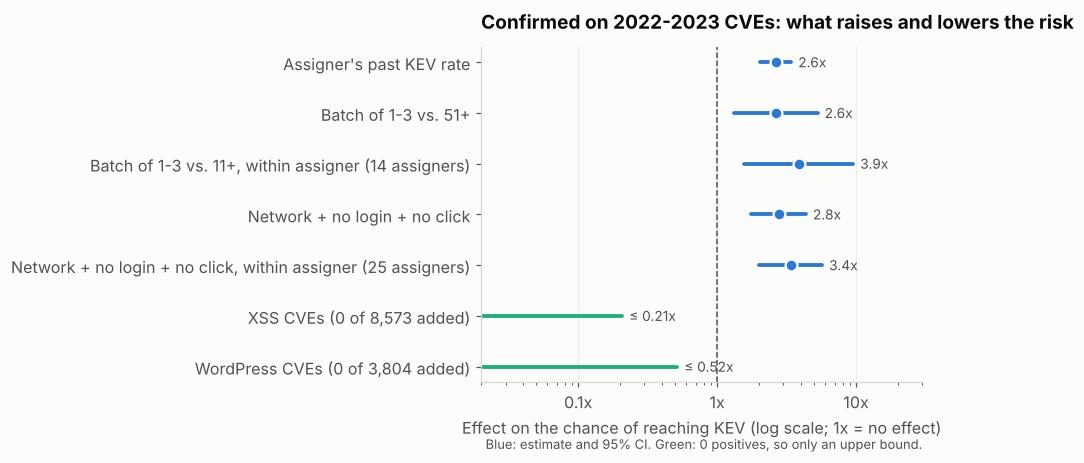

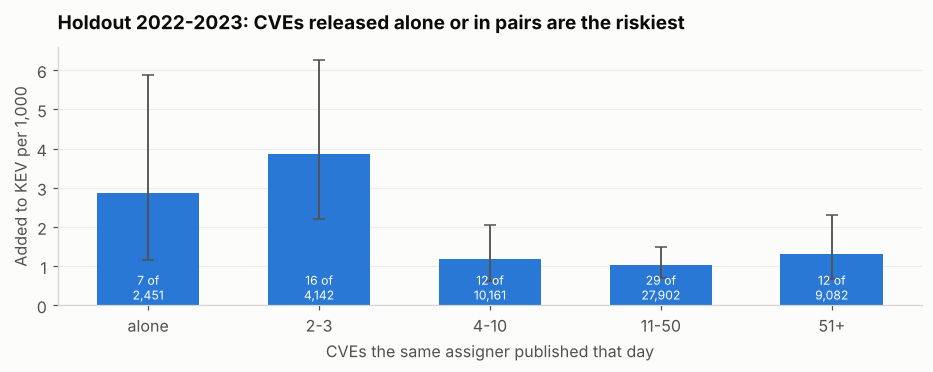

In [5]:
plot = res[res.measure.isin(["odds ratio per 1 SD", "rate ratio", "Mantel-Haenszel OR", "rate ratio (upper bound)"])].iloc[::-1]
fig, ax = plt.subplots(figsize=(8.6, 4.4)); yy = np.arange(len(plot))
for i, (_, r) in enumerate(plot.iterrows()):
    lo, hi = r["95% CI"]
    if r.measure == "rate ratio (upper bound)":
        ax.plot([0.02, hi], [i, i], color=AQUA, lw=2.5, solid_capstyle="round")
        ax.text(hi * 1.12, i, f"≤ {hi:.2f}x", va="center", fontsize=9, color=INK2)
    else:
        ax.plot([lo, hi], [i, i], color=BLUE, lw=2.5, solid_capstyle="round")
        ax.scatter([r.effect], [i], s=60, color=BLUE, zorder=3, edgecolor="#fcfcfb", linewidth=1.5)
        ax.text(hi * 1.12, i, f"{r.effect:.1f}x", va="center", fontsize=9, color=INK2)
ax.axvline(1, color=INK2, lw=1, ls="--"); ax.set_xscale("log"); ax.set_xlim(0.02, 30)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}x"))
ax.set_yticks(yy, plot.finding); ax.grid(axis="y", visible=False)
ax.set_xlabel("Effect on the chance of reaching KEV (log scale; 1x = no effect)")
ax.set_title("Confirmed on 2022-2023 CVEs: what raises and lowers the risk", pad=12)
ax.text(1.0, -0.2, "Blue: estimate and 95% CI. Green: 0 positives, so only an upper bound.", transform=ax.transAxes, ha="right", fontsize=8.5, color=INK2)
plt.tight_layout(); plt.show()

r = H.groupby(groups, observed=False).y.agg(["sum", "size"]); rate = r["sum"] / r["size"] * 1000
cis = np.array([cp_ci(a, b) for a, b in zip(r["sum"], r["size"])]) * 1000
fig, ax = plt.subplots(figsize=(8.6, 3.5))
ax.bar(r.index.astype(str), rate, color=BLUE, width=0.6)
ax.errorbar(np.arange(len(r)), rate, yerr=[rate - cis[:, 0], cis[:, 1] - rate], fmt="none", ecolor=INK2, capsize=4, lw=1.2)
for i, (k_, n_) in enumerate(zip(r["sum"], r["size"])): ax.text(i, 0.15, f"{k_} of\n{n_:,}", ha="center", fontsize=8, color="white")
ax.set_xlabel("CVEs the same assigner published that day"); ax.set_ylabel("Added to KEV per 1,000"); ax.grid(axis="x", visible=False)
ax.set_title("Holdout 2022-2023: CVEs released alone or in pairs are the riskiest", pad=12)
plt.tight_layout(); plt.show()

**What each confirmed finding means** (all survive Holm correction; see the table for exact values)

1. **Who reports the bug predicts exploitation.** Each standard-deviation increase in an assigner's past KEV rate multiplies the odds of a new CVE reaching KEV by about 2.6. *Real world:* attackers keep returning to the same vendors' products, especially enterprise and edge devices, so vendor history is a cheap, day-one triage signal.
2. **Lone and small-batch releases are riskier,** about 2.6x vs. batches of 51+, and the effect holds *within* the same assigner. On the holdout the risk is high for batches of 1-3 and flat beyond. *Real world:* out-of-band, single-CVE advisories often signal urgent fixes; bulk dumps (WordPress plugin sweeps, Patch Tuesday) mostly don't.
3. **Network + no login + no click** is about 2.8x riskier, also within assigners. *Real world:* the profile of mass exploitation.
4. **XSS and WordPress CVEs essentially never reach KEV:** none of 8,573 and 3,804. *Real world:* large-volume categories that can be triaged with lighter processes.
5. **CVSS separates risk less among high scores:** AUC 0.60 within 9+, against 0.71 overall (difference 0.11, 95% CI 0.03-0.18). It still carries some signal there, but most 9+ scores are exactly 9.8. *Real world:* "fix all criticals" can't prioritize well, because most new criticals look identical to CVSS.

**Careful wording for the write-up:** "associated with," not "causes"; "added to KEV" (confirmed exploitation), not "exploited."

## 5. Exploratory signals (2024-2025 only)

These are clear patterns in the years we explored, but they couldn't be confirmed on the holdout, because the monthly exploit signals exist only for 2024-2025. Present them as **exploratory**.

In [6]:
both = pd.concat([tr, va], ignore_index=True)
def per1000(mask):
    s = both[mask]; lo, hi = cp_ci(int(s.y.sum()), len(s))
    return {"CVEs": len(s), "added to KEV": int(s.y.sum()), "per 1,000": round(s.y.mean() * 1000, 1), "95% CI": f"{lo*1000:.1f}-{hi*1000:.1f}"}
signals = pd.DataFrame({
    "no public exploit code": per1000(both.any_exploit == 0),
    "exploit code, EPSS in the month's bottom half": per1000((both.any_exploit == 1) & (both.epss_pct < 0.5)),
    "exploit code, EPSS in the month's top 10%": per1000((both.any_exploit == 1) & (both.epss_pct >= 0.9)),
    "all CVEs": per1000(pd.Series(True, index=both.index))}).T
v25 = va[va.epss.notna()]; early = v25.snap < "2025-03"
print(f"EPSS percentile AUC in 2025: Jan-Feb {roc_auc_score(v25[early].y, v25[early].epss_pct):.2f} ({int(v25[early].y.sum())} positives) "
      f"vs. Mar-Sep {roc_auc_score(v25[~early].y, v25[~early].epss_pct):.2f} ({int(v25[~early].y.sum())} positives)")
signals

EPSS percentile AUC in 2025: Jan-Feb 0.53 (10 positives) vs. Mar-Sep 0.77 (37 positives)


,CVEs,added to KEV,"per 1,000",95% CI
no public exploit code,62726,51,0.8,0.6-1.1
"exploit code, EPSS in the month's bottom half",548,8,14.6,6.3-28.6
"exploit code, EPSS in the month's top 10%",443,22,49.7,31.4-74.2
all CVEs,64120,85,1.3,1.1-1.6


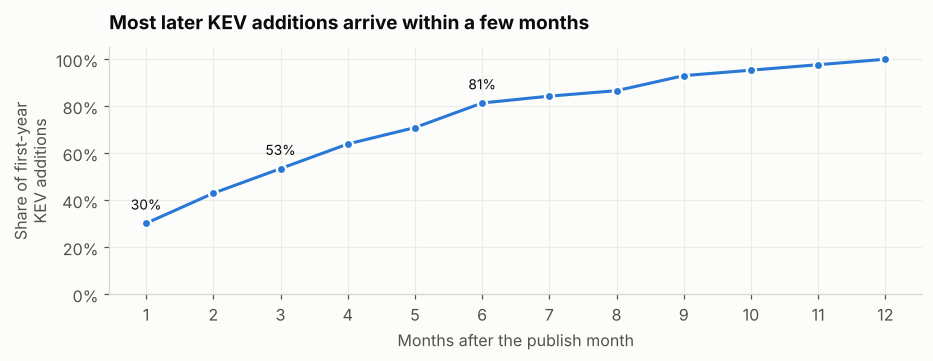

172 KEV additions in the first year after the publish month (CVEs published 2022-2024).


In [7]:
lag = con.sql("""
    WITH k AS (SELECT cve_id, MIN(CAST(date_added AS DATE)) AS d FROM known_exploited GROUP BY 1)
    SELECT datediff('month', date_trunc('month', CAST(v.published AS DATE)), date_trunc('month', k.d)) AS months
    FROM vulnerabilities v JOIN k USING (cve_id)
    WHERE CAST(v.published AS DATE) BETWEEN DATE '2022-01-01' AND DATE '2024-12-31' AND k.d > last_day(CAST(v.published AS DATE))""").df().months
first_year = lag[lag <= 12]
cum = [(first_year <= m).mean() for m in range(1, 13)]
fig, ax = plt.subplots(figsize=(8.6, 3.4))
ax.plot(range(1, 13), cum, color=BLUE, lw=2, marker="o", ms=6, markeredgecolor="#fcfcfb", markeredgewidth=1.5)
for m in (1, 3, 6): ax.annotate(f"{cum[m-1]:.0%}", (m, cum[m-1]), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9, color=INK)
ax.set_ylim(0, 1.05); ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}")); ax.set_xticks(range(1, 13))
ax.set_xlabel("Months after the publish month"); ax.set_ylabel("Share of first-year\nKEV additions")
ax.set_title("Most later KEV additions arrive within a few months", pad=12)
plt.tight_layout(); plt.show()
print(f"{len(first_year)} KEV additions in the first year after the publish month (CVEs published 2022-2024).")

**What these suggest** (exploratory: say so when presenting)
- **Public exploit code is the clearest warning sign.** Even when EPSS ranks a CVE low, exploit code goes with a rate around 15 per 1,000, against under 1 without it. When EPSS agrees, it's around 50 per 1,000. The signals stack.
- **EPSS separated risk better after its March 2025 model change.** That's why EPSS as a feature didn't help a model trained partly on older EPSS values.
- **Timing:** most KEV additions that come after the publish month arrive within a few months (see the chart). The prioritization window is short.

## 6. The model: how it was built and chosen

**Features (14), chosen by evidence.** A feature was kept only if its effect pointed the same way, by a meaningful amount, in *both* 2024 and 2025. Every feature uses only what was known at the snapshot.

| Group | Features | Why |
| --- | --- | --- |
| Exploit signals | `any_exploit`, `poc_github`, `nuclei` | Public exploit code: the strongest signal |
| Assigner history | `log_assigner_kev_rate` | Past KEV rate of whoever issued the CVE (confirmed on holdout) |
| Description and severity | `kw_unauth`, `pr_none`, `ui_none`, `cvss_filled`, `cwe_auth`, `cwe_path` | "Unauthenticated" wording, no privileges or user interaction needed, severity, authentication and path-traversal weaknesses |
| Engineered (LightGBM only) | `net_preauth`, `log_batch_size`, `log_cwe_kev_rate`, `product_has_kev` | Network + no login + no click, release batch size (both confirmed on holdout), weakness-type and product KEV history |

**Models compared:**
- **Logistic regression (LR):** adds up each feature times a learned weight, then converts the total to a probability.
- **LightGBM (GBM):** adds up 200 small decision trees, each correcting the previous ones' errors.
- **Blend:** averages the two models' ranks. *Example:* ranked 100th by LR and 300th by GBM → average rank 200.

**Selection method: repeated, grouped, stratified 5-fold cross-validation** on 2024 + 2025 (85 positives):
1. Split the rows into 5 folds, train on 4 and score the 5th, until every row has an **out-of-fold** score from a model that never saw it.
2. **Stratified:** each fold gets a similar number of positives. **Grouped:** CVEs from the same assigner on the same day stay together, so a model can't learn one bug from an advisory and get tested on its siblings.
3. Rank all rows by their out-of-fold scores, count positives in the top 0.69% (442 rows), and repeat with 5 different random splits.

In [8]:
L = pd.concat([tr.assign(year=2024), va.assign(year=2025)], ignore_index=True).sort_values("cve_id").reset_index(drop=True)
y = L.y.values; is24 = (L.year == 2024).values
NEW4 = ["net_preauth", "log_batch_size", "log_cwe_kev_rate", "product_has_kev"]
GBM = dict(n_estimators=200, learning_rate=0.03, num_leaves=4, max_depth=2, min_child_samples=40, subsample=0.8, subsample_freq=1,
           colsample_bytree=0.8, reg_lambda=5, scale_pos_weight=50, verbose=-1)
def fit_lr(A, B, cols):
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000)).fit(A[cols], A.y).predict_proba(B[cols])[:, 1]
def fit_gbm(A, B, cols, seed=0, n_seeds=3):
    return np.mean([lgb.LGBMClassifier(**GBM, random_state=seed * 10 + s).fit(A[cols], A.y).predict_proba(B[cols])[:, 1] for s in range(n_seeds)], axis=0)
groups = (L.assigner.fillna("?") + "|" + L.published.astype(str)).values
R = 5
oof = {k: np.zeros((R, len(L))) for k in ["LR", "LR + EPSS", "GBM"]}
for r in range(R):
    for f, (a, b) in enumerate(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=r).split(L, y, groups)):
        A, B = L.iloc[a], L.iloc[b]
        oof["LR"][r, b] = fit_lr(A, B, BASE); oof["LR + EPSS"][r, b] = fit_lr(A, B, BASE + ["epss_pct"])
        oof["GBM"][r, b] = fit_gbm(A, B, BASE + NEW4, seed=r * 100 + f)
oof["Blend (LR + GBM)"] = np.array([0.5 * rankdata(oof["LR"][r]) + 0.5 * rankdata(oof["GBM"][r]) for r in range(R)])
base_L = (L.any_exploit * 10 + L.epss.fillna(0)).values
cv = pd.DataFrame({k: {"mean (top 442 of 85 positives)": np.mean([topk(y, v[r]) for r in range(R)]),
                       "per repeat": [topk(y, v[r]) for r in range(R)],
                       "2024 rows (top 199 of 33)": np.mean([topk(y[is24], v[r][is24]) for r in range(R)]),
                       "2025 rows (top 243 of 52)": np.mean([topk(y[~is24], v[r][~is24]) for r in range(R)])} for k, v in oof.items()}).T
cv.loc["Baseline: exploit code then EPSS"] = [topk(y, base_L), [topk(y, base_L)] * R, topk(y[is24], base_L[is24]), topk(y[~is24], base_L[~is24])]
cv

,mean (top 442 of 85 positives),per repeat,2024 rows (top 199 of 33),2025 rows (top 243 of 52)
LR,34.0,"[36, 33, 35, 31, 35]",11.8,21.8
LR + EPSS,34.0,"[35, 31, 34, 35, 35]",11.8,21.8
GBM,30.2,"[30, 31, 32, 29, 29]",14.2,16.2
Blend (LR + GBM),34.6,"[35, 35, 33, 36, 34]",16.4,19.4
Baseline: exploit code then EPSS,22,"[22, 22, 22, 22, 22]",7,14


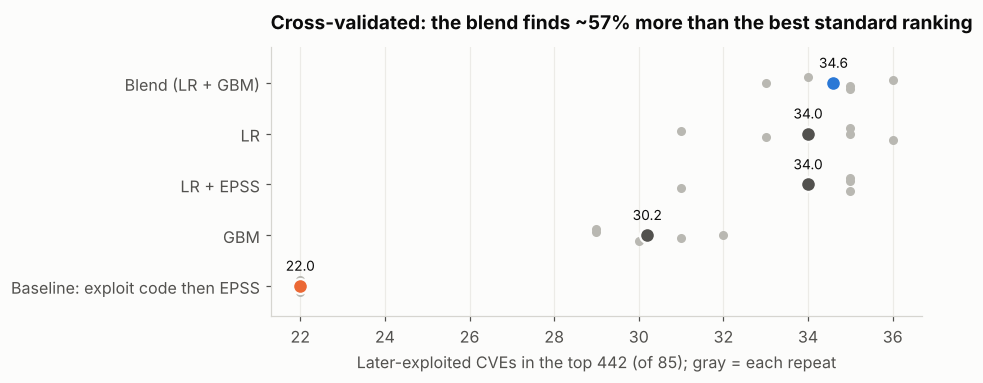

,difference (top 442),90% range,one-sided p
Blend vs. baseline,13,"(6, 21)",0.001
LR vs. baseline,15,"(6, 21)",0.002
GBM vs. baseline,14,"(5, 20)",0.001
Blend vs. LR,-2,"(-6, 6)",0.52


In [9]:
avg = {k: v.mean(axis=0) for k, v in oof.items()}
tests_model = {"Blend vs. baseline": (avg["Blend (LR + GBM)"], base_L), "LR vs. baseline": (avg["LR"], base_L),
               "GBM vs. baseline": (avg["GBM"], base_L), "Blend vs. LR": (avg["Blend (LR + GBM)"], avg["LR"])}
boot = pd.DataFrame({k: dict(zip(["difference (top 442)", "90% range", "one-sided p"], paired_boot(y, *v))) for k, v in tests_model.items()}).T

order = ["Baseline: exploit code then EPSS", "GBM", "LR + EPSS", "LR", "Blend (LR + GBM)"]
fig, ax = plt.subplots(figsize=(8.6, 3.6))
for i, name in enumerate(order):
    pts = cv.loc[name, "per repeat"]; col = ORANGE if name.startswith("Baseline") else (BLUE if name.startswith("Blend") else INK2)
    ax.scatter(pts, np.full(len(pts), i) + np.linspace(-0.12, 0.12, len(pts)), s=24, color=GRAY, zorder=2)
    ax.scatter([np.mean(pts)], [i], s=95, color=col, zorder=3, edgecolor="#fcfcfb", linewidth=1.5)
    ax.text(np.mean(pts), i + 0.3, f"{np.mean(pts):.1f}", ha="center", fontsize=9, color=INK)
ax.set_yticks(range(len(order)), order); ax.grid(axis="y", visible=False); ax.set_ylim(-0.6, len(order) - 0.3)
ax.set_xlabel("Later-exploited CVEs in the top 442 (of 85); gray = each repeat")
ax.set_title("Cross-validated: the blend finds ~57% more than the best standard ranking", pad=12)
plt.tight_layout(); plt.show()
boot

In [10]:
A24, B25 = L[is24], L[~is24]
f_lr, f_gb = fit_lr(A24, B25, BASE), np.mean([fit_gbm(A24.iloc[np.random.default_rng(s).permutation(len(A24))], B25, BASE + NEW4, seed=s, n_seeds=1) for s in range(20)], axis=0)
f_bl = 0.5 * rankdata(f_lr) + 0.5 * rankdata(f_gb)
print(f"Forward check (train 2024 -> test 2025, top 243 of 52): baseline {topk(B25.y, base_L[~is24])}, LR {topk(B25.y, f_lr)}, "
      f"GBM {topk(B25.y, f_gb)}, blend {topk(B25.y, f_bl)}")

Forward check (train 2024 -> test 2025, top 243 of 52): baseline 14, LR 17, GBM 17, blend 18


**What the model selection shows**
- **Every model beats the baseline.** The blend's gain is about **+13 later-exploited CVEs in the top 442** (90% range +6 to +21, one-sided p = 0.001 in the paired bootstrap).
- **Simpler wins with this little data:** plain logistic regression beats LightGBM alone in cross-validation. The blend ties logistic regression (no significant difference) and is chosen because it's more balanced across years and includes batch size, which was confirmed on the holdout.
- **The forward check agrees:** trained only on 2024, the blend beats the baseline on 2025.

**How to say it:** "In repeated, grouped 5-fold cross-validation on 2024-2025, our ranking placed about 35 of 85 later-exploited CVEs in the top 0.69%, against 22 for exploit code then EPSS: +13 (90% range +6 to +21, p = 0.001)."

## 7. The final model and the 2026 top 500

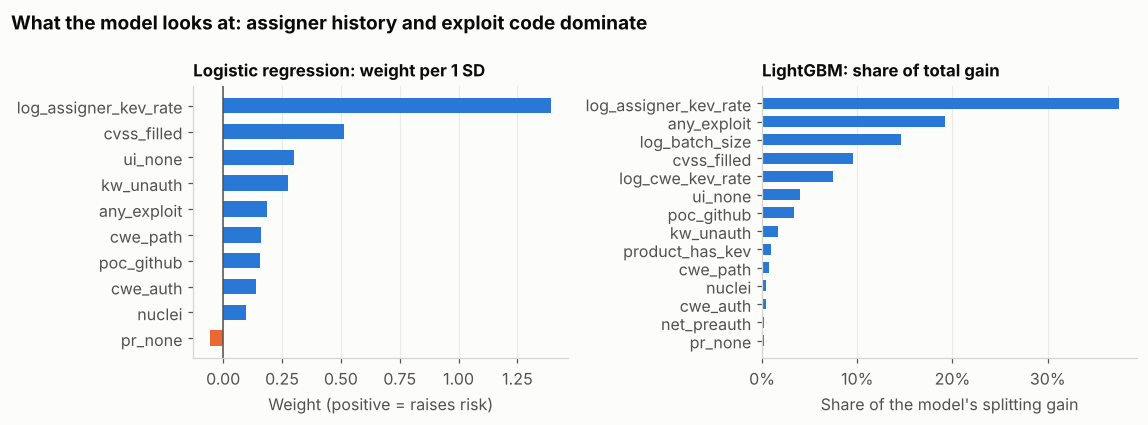

Top 500 - assigners: {'MITRE': 88, 'VulnCheck': 69, 'Apache': 66, 'GitHub': 47, 'Microsoft': 42, 'security@joomla.org': 13}
Top 500 - with public exploit code: 87%; from batches of 51+: 18%; per snapshot month: {'2026-01': 43, '2026-02': 36, '2026-03': 49, '2026-04': 47, '2026-05': 51, '2026-07': 139, '2026-08': 78, '2026-09': 57}
Wrote /tmp/claude-0/-home-claude/df77c833-533d-5f2f-b459-7fe35ac8e99b/scratchpad/data/outputs/top500.csv


In [11]:
lr_final = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000)).fit(L[BASE], y)
sb["p_lr"] = lr_final.predict_proba(sb[BASE])[:, 1]
gbms = [lgb.LGBMClassifier(**GBM, random_state=s).fit(L.iloc[np.random.default_rng(s).permutation(len(L))][BASE + NEW4],
                                                      L.iloc[np.random.default_rng(s).permutation(len(L))].y) for s in range(30)]
sb["p_gbm"] = np.mean([m.predict_proba(sb[BASE + NEW4])[:, 1] for m in gbms], axis=0)
sb["score"] = 0.5 * rankdata(sb.p_lr) / len(sb) + 0.5 * rankdata(sb.p_gbm) / len(sb)

w = pd.Series(lr_final[-1].coef_[0], index=BASE).sort_values()
gain = pd.Series(np.mean([m.booster_.feature_importance("gain") for m in gbms], axis=0), index=BASE + NEW4)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9))
axes[0].barh(w.index, w.values, color=[BLUE if v > 0 else ORANGE for v in w.values], height=0.6)
axes[0].axvline(0, color=INK2, lw=1); axes[0].grid(axis="y", visible=False)
axes[0].set_title("Logistic regression: weight per 1 SD", fontsize=11); axes[0].set_xlabel("Weight (positive = raises risk)")
gn = (gain / gain.sum()).sort_values()
axes[1].barh(gn.index, gn.values, color=BLUE, height=0.6); axes[1].grid(axis="y", visible=False)
axes[1].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].set_title("LightGBM: share of total gain", fontsize=11); axes[1].set_xlabel("Share of the model's splitting gain")
fig.suptitle("What the model looks at: assigner history and exploit code dominate", x=0.01, ha="left", fontsize=12.5, fontweight="bold", color=INK)
plt.tight_layout(); plt.show()

pretty = {"secure@microsoft.com": "Microsoft", "security@apache.org": "Apache", "disclosure@vulncheck.com": "VulnCheck",
          "security-advisories@github.com": "GitHub", "cve@mitre.org": "MITRE", "security@vmware.com": "VMware"}
top = sb.nlargest(500, "score")
print("Top 500 - assigners:", top.assigner.map(lambda a: pretty.get(a, a[:22])).value_counts().head(6).to_dict())
print(f"Top 500 - with public exploit code: {top.any_exploit.mean():.0%}; from batches of 51+: {(top.batch_size > 50).mean():.0%}; "
      f"per snapshot month: {top.snap.value_counts().sort_index().to_dict()}")
OUT = DATA.parent / "outputs"; OUT.mkdir(exist_ok=True)
assert len(top) == 500 and top.cve_id.is_unique and top.cve_id.isin(sb.cve_id).all()
top[["cve_id"]].to_csv(OUT / "top500.csv", index=False)
print("Wrote", OUT / "top500.csv")

**How the model decides.**
- In logistic regression, the assigner's past KEV rate carries by far the largest weight, followed by severity, "no user interaction" and "unauthenticated" wording.
- The exploit-code flags have small weights *individually* because they overlap: most exploit code is a GitHub proof of concept, so the flags share the effect between them.
- In LightGBM, the assigner rate and exploit code account for most of the splitting gain, with batch size and the other engineered features contributing.

**The 2026 list** is diverse (no assigner dominates), and nearly 9 in 10 picks have public exploit code.

## 8. What we tried that didn't help (evidence included)

Reporting these is part of the evidence: each was tested the same way and left out because the data didn't support it.

In [12]:
kev = con.sql("SELECT cve_id, MIN(CAST(date_added AS DATE)) AS d FROM known_exploited GROUP BY 1").df(); kev["d"] = pd.to_datetime(kev.d)
Lk = L[["cve_id", "published", "snap", "year"]].merge(kev, on="cve_id", how="left")
y_nov4 = ((Lk.d > pd.to_datetime(Lk.published) + pd.offsets.MonthEnd(0)) & (Lk.d <= pd.to_datetime(Lk.year.astype(str) + "-11-04"))).astype(int).values
cdf = lambda m: (lag[lag >= 1] <= m).mean()
full = 10 - Lk.snap.str[-2:].astype(int).values
factor = np.array([cdf(f) + (4 / 30) * (cdf(f + 1) - cdf(f)) for f in full])
odds = lambda p: np.clip(p, 1e-9, 1 - 1e-9) / (1 - np.clip(p, 1e-9, 1 - 1e-9))
corr = np.array([0.5 * rankdata(odds(oof["LR"][r]) * factor) + 0.5 * rankdata(odds(oof["GBM"][r]) * factor) for r in range(R)])
dl = {f"{yr}": [np.mean([topk(y_nov4[m], oof["Blend (LR + GBM)"][r][m]) for r in range(R)]), np.mean([topk(y_nov4[m], corr[r][m]) for r in range(R)])]
      for yr, m in [("2024 (top 199)", is24), ("2025 (top 243)", ~is24)]}
tried = pd.DataFrame([
    {"idea": "EPSS as a model feature", "test": "Repeated 5-fold CV (top 442)",
     "result": f"LR {cv.loc['LR'].iloc[0]:.1f} vs. LR + EPSS {cv.loc['LR + EPSS'].iloc[0]:.1f}", "verdict": "not shown; left out"},
    {"idea": "Deadline correction (down-weight late-2026 CVEs)", "test": "Backtest relabelled with a Nov 4 deadline",
     "result": "; ".join(f"{k}: {a:.1f} -> {b:.1f}" for k, (a, b) in dl.items()), "verdict": "not shown; left out"}])
tried

,idea,test,result,verdict
0,EPSS as a model feature,Repeated 5-fold CV (top 442),LR 34.0 vs. LR + EPSS 34.0,not shown; left out
1,Deadline correction (down-weight late-2026 CVEs),Backtest relabelled with a Nov 4 deadline,2024 (top 199): 12.8 -> 11.4; 2025 (top 243): ...,not shown; left out


In [13]:
tb = DATA / "track_b"
if (tb / "text_val_2025.csv").exists():
    t25 = B25.merge(pd.read_csv(tb / "text_val_2025.csv"), on="cve_id", how="left")
    tx = rankdata(t25.text_score.values)
    rows = [{"ranking": "Blend (trained on 2024)", "2025 hits in top 243": topk(B25.y, f_bl)},
            {"ranking": "Granite text model alone", "2025 hits in top 243": topk(B25.y, tx)}]
    for wt in [0.2, 0.33, 0.5]:
        s = (1 - wt) * rankdata(f_bl) + wt * tx; d_, rng_, p_ = paired_boot(B25.y.values, s, f_bl)
        rows.append({"ranking": f"Blend + text (text weight {wt})", "2025 hits in top 243": topk(B25.y, s), "vs. blend": f"{d_:+d} (90% range {rng_[0]:+d} to {rng_[1]:+d})"})
    print(f"Granite text model AUC on 2025: {roc_auc_score(t25.y, t25.text_score):.2f}")
    toptext = t25.nlargest(243, "text_score")
    old_id = toptext.cve_id.str.extract(r"CVE-(\d{4})")[0].astype(int) < 2024
    print(f"Its top 243: {int(toptext.y.sum())} positives; {toptext.any_exploit.mean():.0%} have public exploit code; "
          f"{(toptext.assigner == 'disclosure@vulncheck.com').mean():.0%} are VulnCheck disclosures; {old_id.mean():.0%} carry CVE IDs from before 2024")
    print("Its 5 highest-scored 2025 CVEs:", *toptext.description.str[:95].head(5), sep="\n  - ")
    display(pd.DataFrame(rows).set_index("ranking"))
else:
    print("Granite text-model scores not found in data/track_b/ - skipping this test.")

Granite text model AUC on 2025: 0.85
Its top 243: 5 positives; 7% have public exploit code; 39% are VulnCheck disclosures; 19% carry CVE IDs from before 2024
Its 5 highest-scored 2025 CVEs:
  - Roundcube Webmail before 1.5.10 and 1.6.x before 1.6.11 allows remote code execution by authent
  - Multiple D-Link DIR-series routers, including DIR-110, DIR-412, DIR-600, DIR-610, DIR-615, DIR-
  - An OS command injection vulnerability exists in WebTester version 5.x via the install2.php inst
  - An OS command injection vulnerability exists in various legacy D-Link routers—including DIR-300
  - A buffer underwrite ('buffer underflow') vulnerability in the administrative interface of Forti


,2025 hits in top 243,vs. blend
ranking,,
Blend (trained on 2024),18,NaN
Granite text model alone,5,NaN
Blend + text (text weight 0.2),13,-5 (90% range -9 to +1)
Blend + text (text weight 0.33),10,-8 (90% range -13 to -4)
Blend + text (text weight 0.5),9,-9 (90% range -14 to -4)


**What these mean**
- **EPSS:** useful as a *descriptive* signal (section 5), but it didn't add to the model, likely because its meaning changed in March 2025.
- **Deadline correction:** the reasoning is sound (a September CVE has little time to be added before November 4), but the backtest can't confirm a gain, so the final list is uncorrected.
- **Fine-tuned Granite text model:** it ranks the full list well (AUC 0.85), but it doesn't improve the top 500, and blending it in lowers the hits. The diagnosis: its highest scores go to **disclosures about legacy or discontinued products**, such as old D-Link and Netis routers and a PHP app discontinued in 2009. Many are VulnCheck disclosures, and about a fifth carry old CVE IDs. Their descriptions resemble the famous router exploits in KEV's 2021 launch batch, but these bugs aren't being newly exploited, and few have public exploit code. *Fixes to try:* retrain on 2022-2024 only, or give the model the CVE's age and the product's status.

## 9. Demo talking points

1. **The problem:** severity scores don't say what attackers will hit; standard rankings find 6-8 of the top 500.
2. **How we kept it honest:** a backtest that reproduces the benchmark; a leakage audit that removed NIST review fields (a single "reviewed" flag would have inflated our score); and ideas formed on 2024-2025 but **confirmed on 2022-2023**, with multiple-testing correction.
3. **What we found:** assigner history, small-batch releases and network/no-login/no-click profiles all raise the risk; XSS and WordPress almost never reach KEV; CVSS separates risk less among high scores.
4. **The model:** a blend of logistic regression and LightGBM, chosen by repeated grouped cross-validation; about 57% more later-exploited CVEs found than exploit-code-then-EPSS (p = 0.001).
5. **What didn't work, and why:** EPSS as a feature, a deadline correction, and the Granite text model (it over-scores disclosures about legacy products). Granite still generates the "why fix first" explanations in the demo.
6. **Impact:** a security team gets a ranked list that works from day one, using signals that exist before NIST's review, with a plain-language reason for each pick.

**Columns used:** `description`, `assigner`, `published`, `cvss3_score` (neutral fill), `attack_vector`, `privileges_required`, `user_interaction`, `cwe_ids` (neutral fill); EPSS and exploit flags at the snapshot; KEV dates and product names up to each snapshot. **Not used:** `nvd_status`, `n_affected_cpes`, `n_references`, `cvss3_source`, `last_modified`, `affected_products.csv`, `references.csv`.